# Why FTIR EC does not transfer to Addis: sites, filters, spectral regions and the baseline (2 Nov 2026)

Every number here comes from `workflows/run_transfer_diagnosis_20261102.py`, which reads the 22 Oct decision bundle:
12,393 IMPROVE calibration filters, 233 Addis filters and 3,517 SPARTAN network filters, each as raw, spline (AIRSpec)
and VIBES (87 blanks, rank 70) spectra. Everything is **per filter** (µg). HIPS BC = Fabs × volume / 10.

Models are PLS1 on IMPROVE TOR EC. IMPROVE numbers are **out of site** (5-fold GroupKFold by site). Addis and network numbers
come from the full-pool model. Nothing is tuned on Addis or on SPARTAN HIPS.

**Questions**
1. Which SPARTAN sites behave like Addis, and is Addis really unusual?
2. How much of the Addis slope and intercept against HIPS is in the reference (TOR vs HIPS), and how much is the FTIR model?
3. What does baselining remove, and does it matter?
4. Which part of the spectrum carries the Addis shortfall, and which Addis filters are worst?
5. What can be done, within Ethiopia, with the data we have?

In [1]:
import sys
sys.path.insert(0, './scripts')
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from IPython.display import display
from plotting import PlotConfig  # applies the default white style

T = Path('output/tables/transfer_diagnosis_20261102')
FIG = Path('output/plots/transfer_diagnosis_20261102'); FIG.mkdir(parents=True, exist_ok=True)
pd.set_option('display.width', 220); pd.set_option('display.max_columns', 30)
COL = {'published': '#000000', 'raw': '#1f77b4', 'spline': '#9467bd', 'vibes': '#d62728', 'anchored': '#2ca02c',
       'anchored_noCH': '#17becf', 'anchored_balanced': '#bcbd22', 'vibes_deflate': '#ff7f0e', 'vibes_anchorhp': '#8c564b'}
LABEL = {'published': 'SPARTAN published', 'raw': 'raw', 'spline': 'spline (AIRSpec)', 'vibes': 'VIBES 87 r70',
         'anchored': 'PTFE-anchored', 'anchored_noCH': 'anchored, C–H masked', 'anchored_balanced': 'anchored, OC/EC-balanced',
         'vibes_deflate': 'VIBES, smooth-deflated', 'vibes_anchorhp': 'VIBES on anchored (high-pass)'}
def mid(b):
    lo, hi = b.strip('(]').split(','); return (float(lo) + float(hi)) / 2
print(json.loads((T / 'fit_receipt.json').read_text()))

{'bundle': '/tmp/xfer1102/bundle', 'vibes_model': 'research/ftir_hips_chem/output/tables/network_baselines_20261019/vibes_bundle/background_model.npz', 'k_max': 25, 'cv': 'GroupKFold(5) by IMPROVE site', 'fit_rows': 12387, 'excluded_tor_over_150': 6, 'anchored': {'windows': [[1080, 1290], [590, 690], [500, 580], [2300, 2420]], 'highpass_window_channels': 41, 'ridge': 1e-06}, 'balanced_weights': 'inverse cell count over 10 OC/EC deciles x 6 log-EC bins, clipped at 20', 'created': '2026-11-03T08:29:11Z'}


## 1. Sites: Addis is not alone, and its median ratio is ordinary

SPARTAN's published FTIR EC against HIPS, site by site. The median ratio at Addis is about 0.9, which is unremarkable.
What is unusual is the **gain**: within Addis, FTIR EC rises about twice as fast as HIPS, giving a large negative
intercept. Several other heavily loaded sites show the same pattern (Bujumbura, Dhaka, Santiago, Bandung, Delhi,
Mexico City). Lightly loaded sites show slopes below 1.

,code,n,hips_ug_median,hips_ug_p90,pub_over_hips,ols_slope,ols_intercept_ug,intercept_rel,r2,oc_over_bc
0,PRFJ,40,0.59,1.81,1.44,0.24,1.26,0.87,0.05,5.73
1,USNO,23,2.64,3.56,1.18,0.49,1.85,0.58,0.14,4.04
2,CAHA,40,2.73,4.18,0.88,0.95,0.35,0.11,0.60,5.43
3,USPA,156,3.29,5.18,1.00,0.69,1.03,0.31,0.51,4.20
4,AUMN,51,3.93,10.31,0.74,0.59,0.56,0.16,0.73,2.51
5,CASH,29,3.95,5.61,1.10,1.22,-0.36,-0.08,0.45,4.42
6,ILHA,137,4.34,11.01,0.82,0.68,0.71,0.16,0.71,2.41
7,KRUL,97,4.67,7.13,0.92,0.70,1.45,0.30,0.14,2.82
8,TWTA,193,5.89,9.55,0.81,0.82,-0.06,-0.01,0.80,2.25
9,CLTA,80,6.12,19.63,0.51,1.46,-5.48,-0.72,0.87,2.60


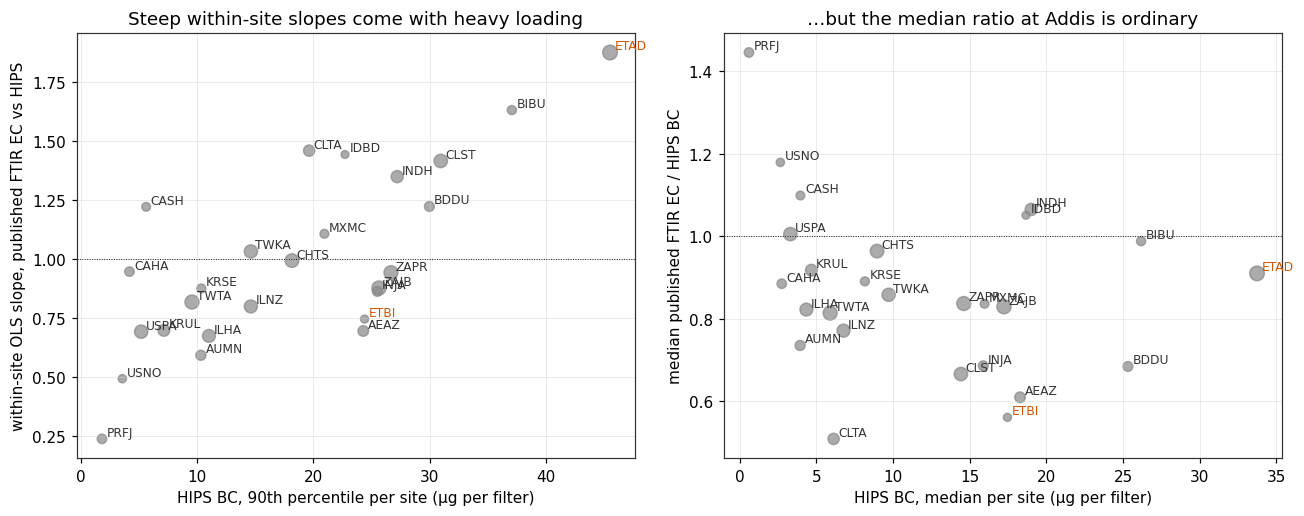

In [2]:
s = pd.read_csv(T / 'sites_published.csv')
display(s.round(2))
fig, ax = plt.subplots(1, 2, figsize=(12, 4.8))
ax[0].scatter(s.hips_ug_p90, s.ols_slope, s=np.sqrt(s.n) * 6, c='#888', alpha=.7)
for _, r in s.iterrows():
    ax[0].annotate(r.code, (r.hips_ug_p90, r.ols_slope), fontsize=8, xytext=(3, 2), textcoords='offset points',
                   color='#d35400' if r.code.startswith('ET') else '#333')
ax[0].axhline(1, color='k', lw=.6, ls=':')
ax[0].set(xlabel='HIPS BC, 90th percentile per site (µg per filter)', ylabel='within-site OLS slope, published FTIR EC vs HIPS',
          title='Steep within-site slopes come with heavy loading')
ax[1].scatter(s.hips_ug_median, s.pub_over_hips, s=np.sqrt(s.n) * 6, c='#888', alpha=.7)
for _, r in s.iterrows():
    ax[1].annotate(r.code, (r.hips_ug_median, r.pub_over_hips), fontsize=8, xytext=(3, 2), textcoords='offset points',
                   color='#d35400' if r.code.startswith('ET') else '#333')
ax[1].axhline(1, color='k', lw=.6, ls=':')
ax[1].set(xlabel='HIPS BC, median per site (µg per filter)', ylabel='median published FTIR EC / HIPS BC',
          title='…but the median ratio at Addis is ordinary')
fig.tight_layout(); fig.savefig(FIG / 'fig1_sites_published.png', dpi=200)

## 2. The reference: TOR / HIPS rises at high loading inside IMPROVE

FTIR is calibrated to TOR, so the fair expectation at a given loading is what TOR would read, not HIPS. In IMPROVE, TOR/HIPS is
about 0.95 from 2–20 µg and climbs to about 1.15 at 20–45 µg and about 1.4 above 45 µg. Low-OC/EC filters, which look like
Addis, behave the same way. Most filters above 30 µg have OP = 0 (the laser saturates), so TOR may itself be high on dark
filters. Either way, a model that perfectly reproduced TOR would show Addis's convex FTIR-vs-HIPS shape.

subset,all,OC/EC<2.5,OC/EC 2.5-5,OC/EC>=5,OP>0,OP=0
hips_bin,,,,,,
"(0, 2]",1.40,1.57,1.58,1.29,1.38,1.74
"(2, 5]",0.97,0.99,0.97,0.98,0.98,0.68
"(5, 10]",0.92,0.89,0.92,0.93,0.92,0.69
"(10, 20]",0.95,0.94,0.95,0.97,0.95,0.80
"(20, 30]",1.12,1.12,1.12,1.28,1.13,1.07
"(30, 45]",1.15,1.18,1.11,2.06,1.24,1.11
"(45, 90]",1.38,1.36,1.14,3.06,2.77,1.35


subset,all,OC/EC<2.5,OC/EC 2.5-5,OC/EC>=5,OP>0,OP=0
hips_bin,,,,,,
"(0, 2]",3432,403,737,2292,3168,264
"(2, 5]",3699,207,1215,2277,3683,16
"(5, 10]",3022,165,1346,1511,3012,10
"(10, 20]",1506,146,815,545,1473,33
"(20, 30]",205,66,97,42,167,38
"(30, 45]",82,32,42,8,34,48
"(45, 90]",26,15,6,5,10,16


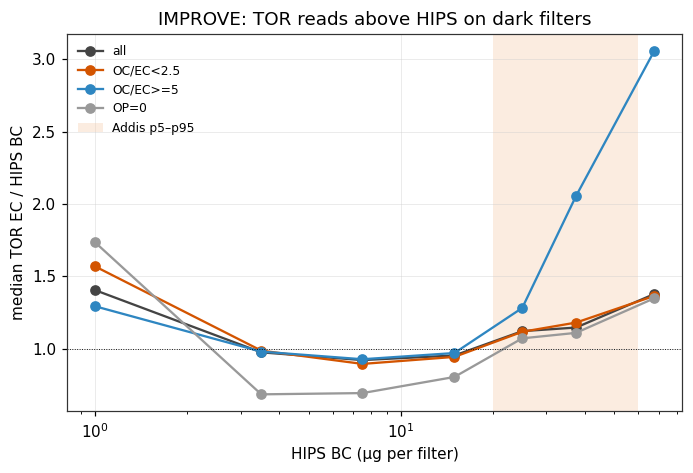

In [3]:
r = pd.read_csv(T / 'improve_tor_over_hips.csv')
piv = r.pivot_table(index='hips_bin', columns='subset', values='median', sort=False)
cnt = r.pivot_table(index='hips_bin', columns='subset', values='n', sort=False)
display(piv.round(2)); display(cnt.astype(int))
fig, ax = plt.subplots(figsize=(6.4, 4.4))
for sub, c in [('all', '#444'), ('OC/EC<2.5', '#d35400'), ('OC/EC>=5', '#2e86c1'), ('OP=0', '#999')]:
    d = r[r.subset == sub]; ax.plot([mid(b) for b in d.hips_bin], d['median'], 'o-', color=c, label=sub)
ax.axhline(1, color='k', lw=.6, ls=':'); ax.set_xscale('log')
ax.set(xlabel='HIPS BC (µg per filter)', ylabel='median TOR EC / HIPS BC', title='IMPROVE: TOR reads above HIPS on dark filters')
ax.axvspan(20, 60, color='#f5cba7', alpha=.35, lw=0, label='Addis p5–p95')
ax.legend(frameon=False, fontsize=8); fig.tight_layout(); fig.savefig(FIG / 'fig2_improve_tor_hips.png', dpi=200)

## 3. Same loading, same composition: Addis against IMPROVE's own heavy low-OC/EC filters

Out-of-site predictions for IMPROVE filters with TOR OC/EC < 2.5, binned by HIPS loading, next to Addis from the same model.
If Addis is "just a heavy, low-OC/EC filter", the two curves should overlap.

* **raw** (SPARTAN's deployed input) and **PTFE-anchored**: Addis reaches 75–100 % of the IMPROVE curve and shares its rise with loading.
* **spline** and **VIBES**: Addis sits far below anything IMPROVE shows at that loading. This part really is specific to Addis, and it depends on the baseline.

what                  Addis OLS intercept vs HIPS (µg)  Addis OLS slope vs HIPS  IMPROVE out-of-site MAE (µg)
model             k                                                                                          
anchored          5                              -9.26                     0.69                          1.28
                  8                             -17.89                     1.21                          1.23
                  12                            -22.12                     1.41                          1.18
                  18                            -24.72                     1.58                          1.12
anchored_balanced 5                             -18.01                     1.14                          1.92
                  8                             -25.29                     1.60                          1.57
                  12                            -35.12                     2.11                          1.85
                  18                            -42.91                     2.41                          1.81
anchored_noCH     5                              -9.30                     0.69                          1.28
                  8                             -17.84                     1.21                          1.23
                  12                            -23.86                     1.52                          1.24
                  18                            -26.03                     1.65                          1.13
raw               5                              -8.21                     0.62                          1.34
                  8                             -13.67                     1.00                          1.37
                  12                            -19.48                     1.31                          1.15
                  18                            -24.15                     1.60                          1.16
spline            5                              -3.48                     0.37                          1.38
                  8                              -5.86                     0.47                          1.26
                  12                             -5.50                     0.49                          1.18
                  18                             -8.45                     0.63                          1.09
vibes             5                              -5.58                     0.43                          1.34
                  8                             -17.86                     1.03                          1.25
                  12                            -25.94                     1.39                          1.14
                  18                            -34.41                     1.72                          1.15
vibes_anchorhp    5                              -9.24                     0.69                          1.28
                  8                             -17.80                     1.21                          1.22
                  12                            -22.13                     1.41                          1.17
                  18                            -25.31                     1.59                          1.10
vibes_deflate     5                              -4.52                     0.44                          1.53
                  8                              -9.79                     0.71                          1.53
                  12                            -17.34                     1.03                          1.51
                  18                            -18.86                     1.11                          1.34

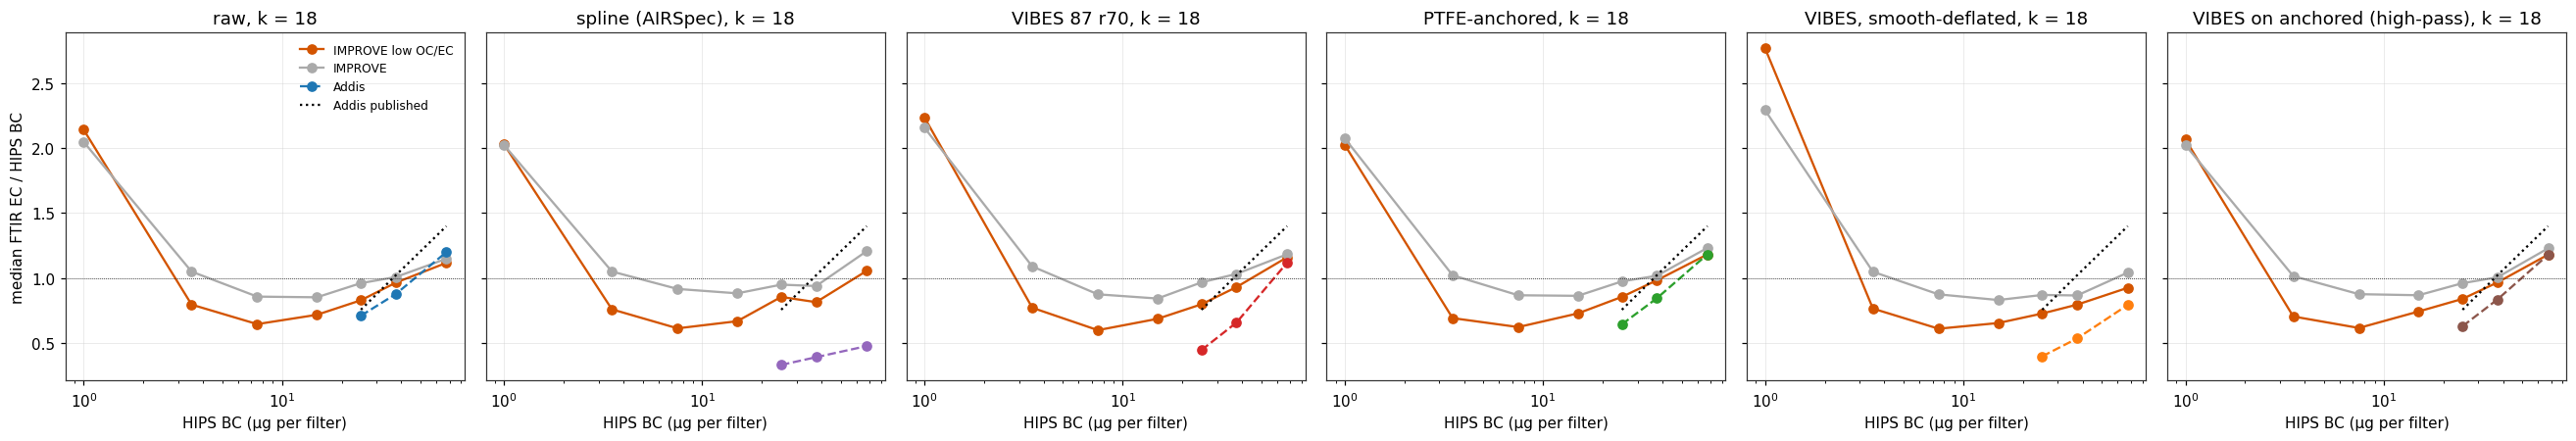

In [4]:
R = pd.read_csv(T / 'ratios_by_loading.csv')
models = [m for m in ['raw', 'spline', 'vibes', 'anchored', 'vibes_deflate', 'vibes_anchorhp'] if m in set(R.model)]
fig, axs = plt.subplots(1, len(models), figsize=(4 * len(models), 4.2), sharey=True)
for ax, m in zip(axs, models):
    for what, ls, c in [('IMPROVE low OC/EC FTIR/HIPS', '-', '#d35400'), ('IMPROVE FTIR/HIPS', '-', '#aaa'), ('Addis FTIR/HIPS', '--', COL[m])]:
        d = R[(R.model == m) & (R.k == 18) & (R.what == what) & (R.n >= 5)]
        ax.plot([mid(b) for b in d.hips_bin], d['median'], 'o' + ls, color=c, label=what.replace(' FTIR/HIPS', ''))
    d = R[(R.model == 'published') & (R.what == 'Addis FTIR/HIPS') & (R.n >= 5)]
    ax.plot([mid(b) for b in d.hips_bin], d['median'], 'k:', label='Addis published')
    ax.axhline(1, color='k', lw=.5, ls=':'); ax.set_xscale('log'); ax.set_title(f'{LABEL[m]}, k = 18')
    ax.set_xlabel('HIPS BC (µg per filter)')
axs[0].set_ylabel('median FTIR EC / HIPS BC'); axs[0].legend(frameon=False, fontsize=8)
fig.tight_layout(); fig.savefig(FIG / 'fig3_matched_loading.png', dpi=200)
tab = R[(R.what.isin(['IMPROVE out-of-site MAE (µg)', 'Addis OLS slope vs HIPS', 'Addis OLS intercept vs HIPS (µg)']))]
display(tab.pivot_table(index=['model', 'k'], columns='what', values='median').round(2))

## 4. Baselining removes the most direct EC signal: the broad IR continuum

Black carbon absorbs across the mid-IR, so loaded filters carry a smooth continuum that grows with loading (raw panel). The
spline removes all of it by construction. The current VIBES background, whose blank components span smooth ramps and whose
pinball loss pushes the background to the spectrum's floor, removes almost all of it.

Per µg of HIPS, Addis has about the same continuum as IMPROVE at 1880–2050 cm⁻¹, where absorption dominates, but less at
3900 cm⁻¹, where scattering adds. That fits black-carbon absorption.

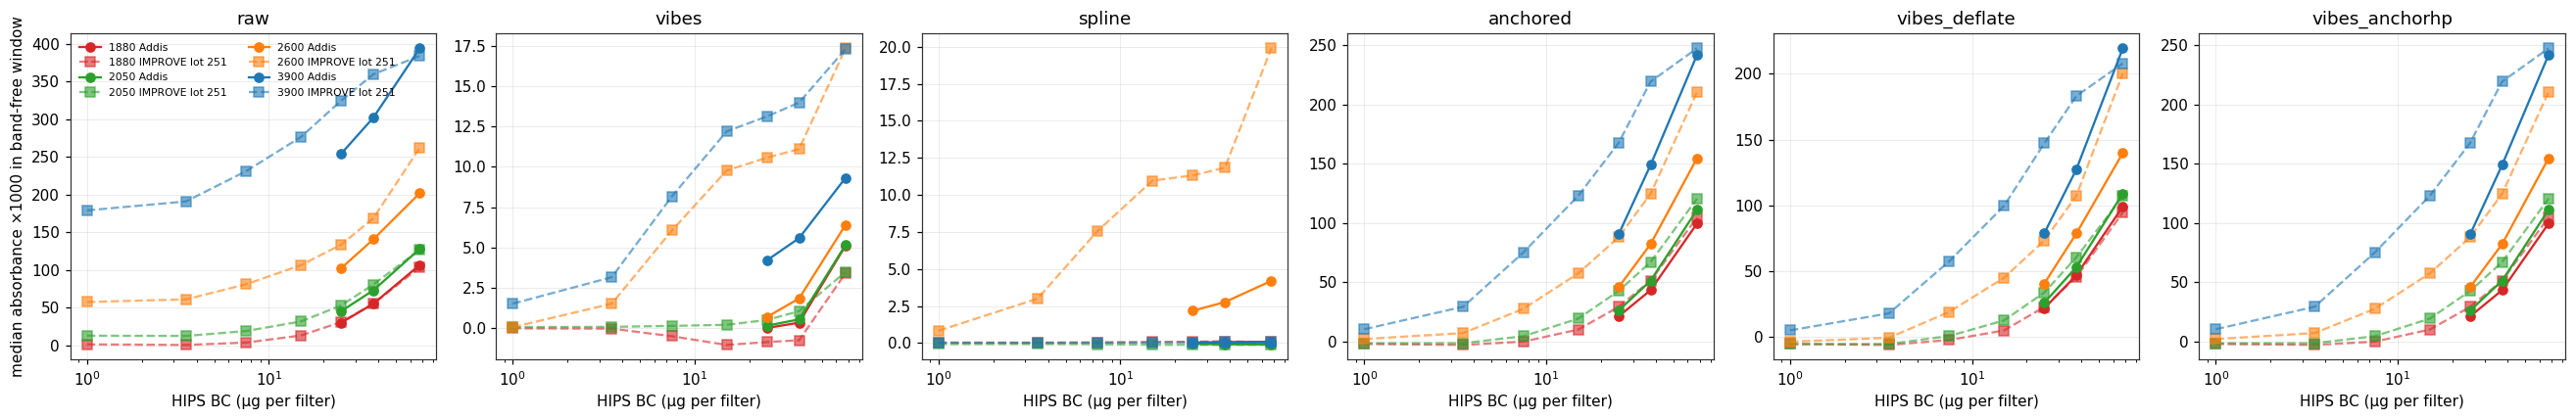

In [5]:
cb = pd.read_csv(T / 'continuum_by_loading.csv')
preps = [p for p in ['raw', 'vibes', 'spline', 'anchored', 'vibes_deflate', 'vibes_anchorhp'] if p in set(cb.prep)]
fig, axs = plt.subplots(1, len(preps), figsize=(4 * len(preps), 4), sharey=False)
for ax, prep in zip(axs, preps):
    for (win, grp), d in cb[(cb.prep == prep) & (cb.n >= 5)].groupby(['window', 'group']):
        if grp == 'IMPROVE lot 248': continue
        ax.plot([mid(b) for b in d.hips_bin], d['median'] * 1e3, 'o-' if grp == 'Addis' else 's--',
                color={'3900': '#1f77b4', '2600': '#ff7f0e', '2050': '#2ca02c', '1880': '#d62728'}[str(win)],
                label=f'{win} {grp}', alpha=1 if grp == 'Addis' else .6)
    ax.set_xscale('log'); ax.set_title(prep); ax.set_xlabel('HIPS BC (µg per filter)')
axs[0].set_ylabel('median absorbance ×1000 in band-free window'); axs[0].legend(frameon=False, fontsize=7, ncol=2)
fig.tight_layout(); fig.savefig(FIG / 'fig4_continuum.png', dpi=200)

### 4b. Two direct checks of VIBES and of the alternative

**Injection test.** A smooth continuum (0.05 absorbance at 2000 cm⁻¹) is added to 16 light IMPROVE filters, and real VIBES
is rerun with the saved 87-blank rank-70 background. The production background returns **under 1 %** of a BC-like ν¹
continuum. Taking the smooth directions out of the blank components returns all of it, but leaves about 16× more residual
on light filters, because lot-to-lot PTFE differences live in the same smooth shapes.

**Noise floor.** On light filters, blank-to-blank continuum scatter is worth **3–6 µg EC** with lot-mean subtraction. The IMPROVE median filter
holds 3.7 µg, so an IMPROVE-trained model rightly treats the continuum as noise and leans on organic bands. Addis filters
hold about 34 µg, so there the continuum is the strongest EC signal. The **PTFE-anchored** background fits the blank-component
scores only on the high-passed PTFE bands. It cuts the scatter to 1.1–1.9 µg, removes the lot offset and keeps the continuum
(`scripts/continuum_anchor.py`).

In [6]:
inj = pd.read_csv(T / 'vibes_injection.csv')
display(inj.groupby(['variant', 'shape']).value.median().unstack().round(4))
noise = pd.read_csv(T / 'continuum_noise.csv')
display(noise.pivot_table(index=['window', 'lot'], columns='prep', values='noise_ug').round(1).rename(columns=lambda c: c + ' (µg EC equiv.)'))

shape,flat,light-filter residual RMS,nu^1 (BC-like),nu^2 (scattering-like)
variant,,,,
"minus 1, nu, nu^2",1.0000,0.0292,1.0000,1.0000
minus nu^1 direction,0.7565,0.0289,1.0000,1.0160
production (rank 70),0.0033,0.0018,0.0066,0.0051


prep        anchored (µg EC equiv.)  raw minus lot mean (µg EC equiv.)
window lot                                                            
1880   248                      1.9                                5.4
       251                      1.6                                2.7
2050   248                      1.7                                5.4
       251                      1.2                                3.2
2600   248                      1.3                                6.0
       251                      1.1                                3.9
3900   248                      1.2                                6.5
       251                      1.8                                6.0

## 5. Where in the spectrum the Addis shortfall sits

Each model's EC prediction is split into wavenumber windows (coefficient × centred absorbance, per µg of HIPS). The chart
shows Addis minus matched IMPROVE filters (low OC/EC, HIPS 20–60 µg, mostly BIRM1, PHOE1, ATLA1, PITT1, PUSO1), at k = 12.
Negative means Addis gets less EC from that window.

In every baseline the largest deficit is the **aliphatic C–H stretch (3000–2800 cm⁻¹)**: the models use organic C–H as a
stand-in for EC, and Addis has less C–H per unit of BC than even IMPROVE's urban low-OC/EC filters. Only raw and anchored
recover part of it, from the continuum windows (2800–2400 and 4000–3700 cm⁻¹).

,model,raw,spline,vibes,anchored,vibes_deflate,vibes_anchorhp
hi,lo,,,,,,
4000,3700,-0.104,0.001,0.072,0.229,-0.235,0.228
3700,3400,-0.055,0.027,-0.008,-0.364,0.401,-0.364
3400,3100,0.014,0.468,0.074,0.113,0.031,0.114
3100,3000,0.094,-0.601,0.033,0.020,0.178,0.020
3000,2800,-0.708,-0.348,-0.343,-0.743,-0.964,-0.744
2800,2600,0.272,0.179,0.045,0.226,0.262,0.227
2600,2400,0.218,-0.041,0.018,0.216,0.126,0.217
2400,2300,0.056,-0.025,0.001,0.064,0.006,0.064
2300,2000,0.011,-0.005,-0.005,0.028,-0.005,0.028


sum: {'raw': -0.19, 'spline': -0.45, 'vibes': -0.25, 'anchored': -0.26, 'vibes_deflate': -0.22, 'vibes_anchorhp': -0.26}


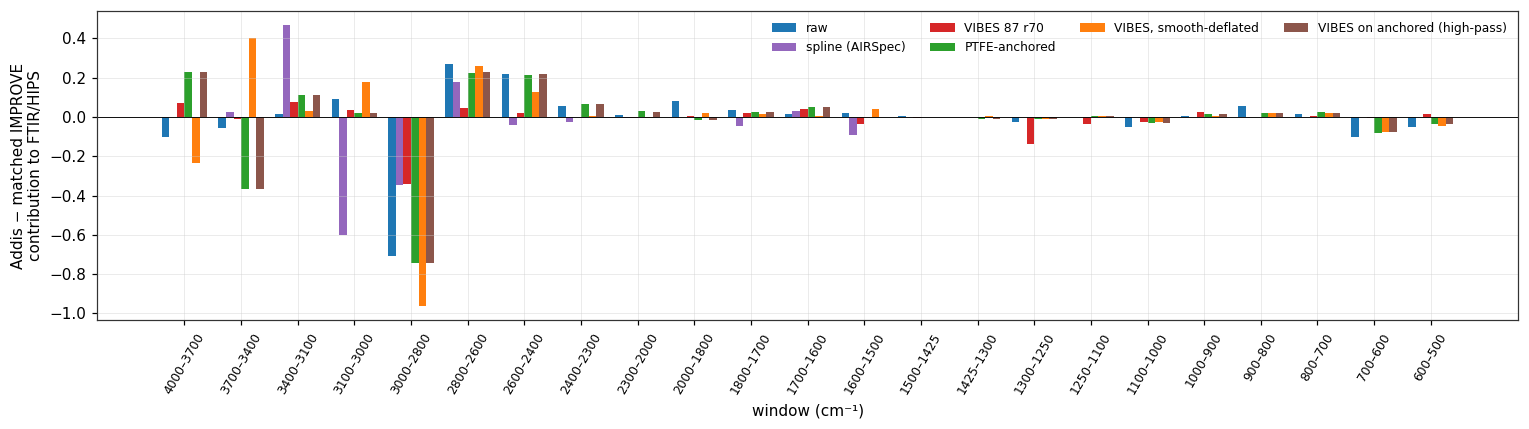

In [7]:
wa = pd.read_csv(T / 'window_attribution.csv')
piv = wa.pivot_table(index=['hi', 'lo'], columns='model', values='difference', sort=False).sort_index(ascending=False)
display(piv.round(3)); print('sum:', piv.sum().round(2).to_dict())
fig, ax = plt.subplots(figsize=(14, 4))
labels = [f'{h}–{l}' for h, l in piv.index]; x = np.arange(len(labels)); ms = list(piv.columns); wdt = .8 / len(ms)
for j, m in enumerate(ms):
    ax.bar(x + (j - (len(ms) - 1) / 2) * wdt, piv[m].fillna(0), wdt, color=COL[m], label=LABEL[m])
ax.axhline(0, color='k', lw=.6); ax.set_xticks(x, labels, rotation=60, fontsize=8)
ax.set(ylabel='Addis − matched IMPROVE\ncontribution to FTIR/HIPS', xlabel='window (cm⁻¹)')
ax.legend(frameon=False, ncol=4, fontsize=8); fig.tight_layout(); fig.savefig(FIG / 'fig5_window_attribution.png', dpi=200)

## 6. Every site against the TOR yardstick

The yardstick for each filter is the median TOR/HIPS of IMPROVE filters at the same loading and OC/BC, from a small
gradient-boosted fit. The table shows each site's median FTIR / (HIPS × yardstick): 1.0 means the site reads the way TOR would
read it. At Addis, Bishoftu and Dhaka the OC/BC is below IMPROVE's range for a third to half of the filters, so their yardstick
is an extrapolation. Treat their numbers as ±20 %.

* **Under-read by every model:** Bishoftu (ETBI), Jaipur (INJA), Bujumbura (BIBU), Tarapacá (CLTA), Dhaka (BDDU), Santiago (CLST).
* **Spline collapses (about 0.4)** at exactly ETAD, ETBI and BDDU, the low-OC/BC sites.
* **Anchored versus VIBES** gains most at ETAD (0.67→0.87), CLST (0.70→0.94), ZAPR (0.84→0.99) and ETBI/INJA (+0.04 to +0.10).

,n,hips_ug,oc_over_bc,share_oc_bc_outside_improve,expected_tor_over_hips,published,raw k18,spline k18,vibes k18,anchored k18,anchored_noCH k18,anchored_balanced k12,vibes_deflate k18,vibes_anchorhp k18
code,,,,,,,,,,,,,,
ETBI,21,17.45,1.20,0.52,0.73,0.71,0.62,0.41,0.58,0.62,0.62,0.76,0.50,0.60
BIBU,34,26.17,2.92,0.00,1.08,0.95,0.79,0.75,0.63,0.71,0.71,0.74,0.66,0.71
INJA,47,15.88,1.33,0.34,0.73,0.96,0.85,0.62,0.64,0.74,0.74,0.67,0.65,0.71
ETAD,231,33.73,1.20,0.50,0.90,1.02,0.91,0.41,0.67,0.87,0.90,1.07,0.54,0.86
CLTA,71,7.07,2.57,0.01,0.76,0.66,0.74,0.90,0.68,0.70,0.68,0.52,0.79,0.71
CLST,163,14.42,1.65,0.07,0.73,0.90,0.97,0.74,0.70,0.94,0.88,0.79,0.69,0.90
BDDU,46,25.32,1.31,0.33,0.89,0.78,0.84,0.44,0.76,0.79,0.77,0.97,0.52,0.79
ZAJB,201,17.26,1.88,0.03,0.79,1.02,0.91,0.73,0.81,0.89,0.89,0.93,0.72,0.89
AUMN,38,5.87,2.17,0.03,0.73,0.95,1.13,0.86,0.84,1.00,0.95,0.88,0.81,1.03


Addis by season (ratio to yardstick):


,published,raw k18,spline k18,vibes k18,anchored k18,anchored_noCH k18,anchored_balanced k12,vibes_deflate k18,vibes_anchorhp k18
season,,,,,,,,,
Belg (Mar-May),1.01,0.93,0.41,0.67,0.87,0.90,1.08,0.55,0.86
Dry (Oct-Feb),0.83,0.77,0.36,0.54,0.74,0.76,0.93,0.44,0.73
Kiremt (Jun-Sep),1.24,1.09,0.46,0.96,1.05,1.09,1.34,0.71,1.05


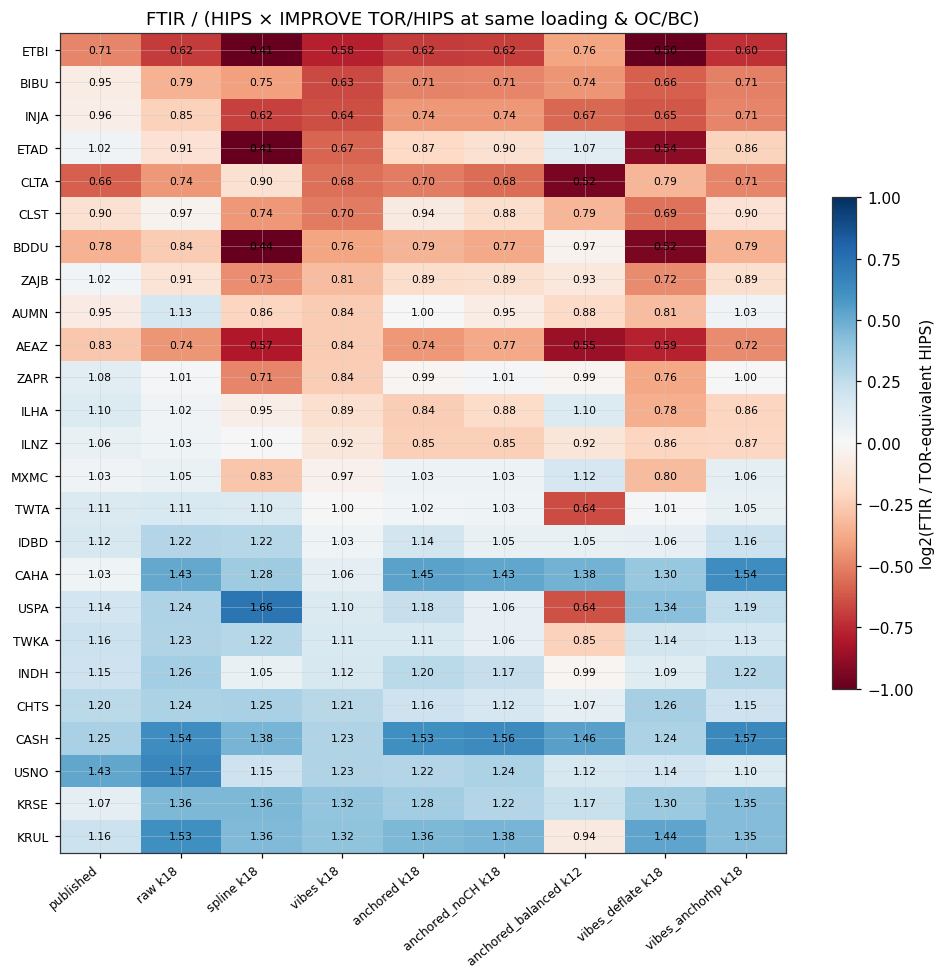

In [8]:
sv = pd.read_csv(T / 'sites_vs_tor_yardstick.csv').set_index('code')
cols = [c for c in ['published', 'raw k18', 'spline k18', 'vibes k18', 'anchored k18', 'anchored_noCH k18', 'anchored_balanced k12',
                    'vibes_deflate k18', 'vibes_anchorhp k18'] if c in sv.columns]
sv = sv[sv.n >= 15].sort_values('vibes k18')
display(sv.round(2))
fig, ax = plt.subplots(figsize=(9, 9))
im_ = ax.imshow(np.log2(sv[cols].to_numpy()), cmap='RdBu', vmin=-1, vmax=1, aspect='auto')
ax.set_xticks(range(len(cols)), cols, rotation=40, ha='right', fontsize=8); ax.set_yticks(range(len(sv)), sv.index, fontsize=8)
for i in range(len(sv)):
    for j, c in enumerate(cols):
        ax.text(j, i, f'{sv[c].iloc[i]:.2f}', ha='center', va='center', fontsize=7)
cb_ = fig.colorbar(im_, ax=ax, shrink=.6); cb_.set_label('log2(FTIR / TOR-equivalent HIPS)')
ax.set_title('FTIR / (HIPS × IMPROVE TOR/HIPS at same loading & OC/BC)')
fig.tight_layout(); fig.savefig(FIG / 'fig6_sites_yardstick.png', dpi=200)
nf = pd.read_csv(T / 'network_filters.csv')
a = nf[nf.code == 'ETAD']
print('Addis by season (ratio to yardstick):')
display(a.groupby('season')[cols].apply(lambda d: (d.div(a.loc[d.index, 'exp_tor_hips'], axis=0)).median()).round(2))

## 7. Within Addis: which filters, and what they share

Residual of the anchored k18 model after removing the within-Addis loading trend. Under-read filters have **less IR-visible
material per unit of HIPS absorption**: low OC/BC, low PM/BC and low K/BC. Dust and sulfate do not matter. The residual
correlates with absorbance per µg HIPS at every wavenumber (ρ ≈ 0.8 above 1400 cm⁻¹). It is seasonal: Oct–Jan lowest,
Jun–Sep highest. The two worst filters, ETAD-0037 and ETAD-0139, are already listed in `docs/open-items.md` as bad scans, so
the same residual works as a QC flag.

{'oc_ftir/BC': np.float64(0.68), 'pm25/BC': np.float64(0.51), 'k_xrf/BC': np.float64(0.35), 'si/BC': np.float64(-0.16), 'al/BC': np.float64(-0.1), 'fe/BC': np.float64(-0.12), 'so4/BC': np.float64(0.0)}


,filter_id,date,season,hips_ug,resid
18,ETAD-0037,2023-01-09,Dry (Oct-Feb),26.99,-1.21
101,ETAD-0139,2023-11-14,Dry (Oct-Feb),37.02,-0.66
200,ETAD-0262,2025-01-25,Dry (Oct-Feb),36.27,-0.57
199,ETAD-0261,2025-01-16,Dry (Oct-Feb),41.93,-0.49
225,ETAD-0304,2025-12-09,Dry (Oct-Feb),36.39,-0.44
196,ETAD-0258,2024-12-20,Dry (Oct-Feb),41.32,-0.42
223,ETAD-0301,2025-12-03,Dry (Oct-Feb),35.77,-0.40
211,ETAD-0277,2025-05-15,Belg (Mar-May),40.81,-0.39
7,ETAD-0001,2023-01-21,Dry (Oct-Feb),38.38,-0.39
222,ETAD-0300,2025-11-30,Dry (Oct-Feb),31.15,-0.39


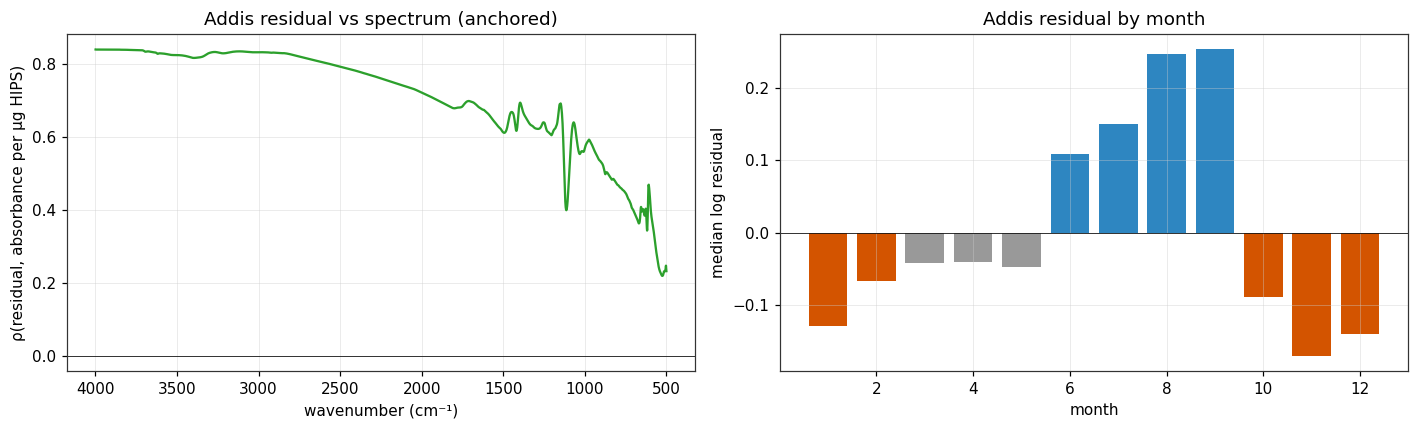

In [9]:
ar = pd.read_csv(T / 'addis_residuals.csv')
bc = ar.fabs_Mm1 / 10
chem = {c: ar[c] / bc for c in ['oc_ftir_ugm3', 'pm25_ugm3', 'k_xrf_ugm3', 'si_ugm3', 'al_ugm3', 'fe_ugm3', 'so4_ugm3']}
print({k.replace('_ugm3', '') + '/BC': round(ar.resid.corr(v, method='spearman'), 2) for k, v in chem.items()})
rs = pd.read_csv(T / 'addis_residual_spectrum.csv')
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].plot(rs.wn, rs.rho, color='#2ca02c'); ax[0].invert_xaxis(); ax[0].axhline(0, color='k', lw=.5)
ax[0].set(xlabel='wavenumber (cm⁻¹)', ylabel='ρ(residual, absorbance per µg HIPS)', title='Addis residual vs spectrum (anchored)')
mo = ar.groupby('month').resid.agg(['median', 'size'])
ax[1].bar(mo.index, mo['median'], color=['#2e86c1' if m in (6, 7, 8, 9) else '#d35400' if m in (10, 11, 12, 1, 2) else '#999' for m in mo.index])
ax[1].axhline(0, color='k', lw=.5); ax[1].set(xlabel='month', ylabel='median log residual', title='Addis residual by month')
fig.tight_layout(); fig.savefig(FIG / 'fig7_addis_residuals.png', dpi=200)
display(ar.sort_values('resid')[['filter_id', 'date', 'season', 'hips_ug', 'resid']].head(10).round(2))

## What this means

1. **Most of the Addis slope and intercept against HIPS is not an FTIR failure.** IMPROVE's own heavy, low-OC/EC filters show
   the same convex FTIR-vs-HIPS shape, because TOR rises faster than HIPS above about 20 µg per filter. Judged against "slope 1,
   intercept 0 against HIPS", no TOR-trained model can pass at Addis. The fair test is FTIR / (HIPS × IMPROVE TOR/HIPS at the
   same loading and composition), section 6.
2. **What is left is a level shortfall that depends on the baseline.** Against that yardstick SPARTAN's published (raw)
   product is roughly right on average at Addis (Dry about 0.8, Kiremt about 1.2). VIBES reads about 0.7 and spline about 0.4.
3. **The mechanism.** IMPROVE filters are too light for the broad black-carbon continuum to rise above blank-to-blank PTFE
   noise, so IMPROVE-trained models infer EC from organic C–H and O–H bands. Addis has 9× the loading and the lowest OC/EC in
   either network, so the proxy under-reads there, and most of all in the Dry season. Spline and VIBES remove the continuum
   that could have corrected it.
4. **Not only Ethiopia.** Bishoftu, Dhaka, Jaipur, Bujumbura, Santiago and Tarapacá show the same under-read. Korea, Beijing,
   Bandung and Delhi read high.

## What we can do, within Ethiopia, with the data we have

* **Replace the VIBES background with a continuum-preserving one.** The PTFE-anchored background here fits IMPROVE best out of
  site (MAE 1.12 µg, against 1.16 raw and 1.15 VIBES). It moves Addis from 0.67 to 0.87 of the TOR yardstick, and Santiago
  and Pretoria to about 1. Next, build the same idea into VIBES itself (below).
* **Reduce reliance on the organic proxy.** Masking C–H costs nothing in IMPROVE and helps a little. OC/EC-balanced weights
  close most of the Addis level gap but worsen overall IMPROVE accuracy (MAE 1.8 µg), so use them as a sensitivity bound, not
  the product.
* **Report Addis against the TOR yardstick, by season,** and stop quoting slope and intercept against HIPS as the failure
  metric. Keep HIPS as a cross-check.
* **Use the Addis city TOR filters as a one- or two-parameter check, not a calibration set.** Ten filters cannot support a
  local PLS. They can test whether the continuum term (or the anchored model's level) is right at Addis loading. Before
  reading them, write down what counts as a pass (`docs/research-questions-2026-10.md`).
* **Use Bishoftu (ETBI) as the in-country holdout.** It is the lowest-reading site in the network and is untouched by any fit.
* **QC flag:** the within-Addis residual against absorbance per µg HIPS (section 7) picks out the known bad scans first.

## Colab rerun: real VIBES with continuum-protected backgrounds (3 Nov 2026)

`workflows/vibes_continuum_20261102.py` reran real VIBES (tau 0.1, PB loss, maxiter 10000) on all 16,143 spectra with two
backgrounds. That is 32,286 fits on one Colab G4 VM (48 vCPUs, about 960 fits/min, about 34 min). None failed. VIBES is a
CPU convex solve, so the VM's GPU sat idle; the VM was chosen for its cores.

* **`vibes_anchorhp`**: VIBES on the PTFE-anchored spectrum, with the blank components high-passed so it removes only the
  remaining sharp blank structure. IMPROVE out-of-site MAE is 1.10 µg (production VIBES 1.15). Addis reads 0.86 of the TOR
  yardstick (production VIBES 0.67). It matches the linear anchored background almost exactly, so the gain comes from
  anchoring and VIBES' positivity adds little on top.
* **`vibes_deflate`**: VIBES with the smooth directions (1, ν, ν²) projected out of the blank components. This is worse
  (IMPROVE MAE 1.34 µg, Addis 0.54): with nothing to model the smooth PTFE background, lot and thickness differences flood
  into the spectrum. Protecting the continuum only works if the PTFE background is still predicted from the PTFE bands.

**Recommendation:** use the anchored background (or `vibes_anchorhp`) as the continuum-preserving baseline from now on, in
place of production VIBES. Sections 3–6 above include both variants.

## 8. The intercept that is left (3 Nov 2026)

`workflows/run_intercept_fixes_20261103.py` (stages attrib, fit, tables, aeth → `output/tables/intercept_fixes_20261103/`).
On `vibes_anchorhp`, Addis still reads 1.86x HIPS − 4.80 µg/m³. Three questions:

1. Where does it come from? Addis HIPS spans only 3.4–6.8 µg/m³, so the intercept mirrors the slope:
   intercept ≈ −(slope − ratio) × mean HIPS. The question becomes which windows give the excess day-to-day gain.
2. Can a label-free change to the calibration remove it? Six candidates, all trained on IMPROVE TOR EC only. Addis HIPS is
   never used to fit or choose. Two of them see the unlabeled Addis spectra.
3. Is it the FTIR at all? The Addis MA350 aethalometer (IR BCc over each filter's 24 h) is a third instrument on its own
   inlet, so it can say whether FTIR or HIPS follows Addis's day-to-day BC.

In [10]:
I = Path('output/tables/intercept_fixes_20261103')
g = pd.read_csv(I / 'window_gain.csv')
piv = g[g.k == 18].pivot_table(index='window', columns='model', values='slope_hips_bc', sort=False)
display(piv.round(2)); print('total OLS slope vs HIPS:', piv.sum().round(2).to_dict())
sw = pd.read_csv(I / 'summary.csv')
cols = ['model', 'k', 'improve_mae', 'improve_heavy_lowocec_ratio', 'slope_hips_bc', 'intercept_hips_bc', 'ratio_tor_equiv',
        'intercept_aeth_rel', 'loglog_aeth']
display(sw[sw.k.isin([10, 18]) & (sw.model != 'base')][cols].round(3))

model,vibes,vibes_anchorhp
window,,
4000-3700,-0.13,-2.41
3700-3400,0.05,2.57
3400-3100,0.07,-1.08
3100-3000,-0.02,1.20
3000-2800,0.13,2.47
2800-2600,0.03,-0.59
2600-2400,0.06,-1.01
2400-2300,-0.00,-0.71
2300-2000,0.12,-1.16


total OLS slope vs HIPS: {'vibes': 1.72, 'vibes_anchorhp': 1.59}


,model,k,improve_mae,improve_heavy_lowocec_ratio,slope_hips_bc,intercept_hips_bc,ratio_tor_equiv,intercept_aeth_rel,loglog_aeth
9,vibes,10,1.158,0.654,1.405,-3.989,0.544,-0.170,1.179
17,vibes,18,1.154,0.747,2.031,-6.270,0.661,-0.281,1.283
34,vibes_anchorhp_full,10,1.184,0.708,1.546,-3.755,0.773,0.050,0.972
42,vibes_anchorhp_full,18,1.101,0.785,1.857,-4.798,0.857,0.010,0.997
79,cont_only,10,1.384,0.513,0.661,-0.944,0.488,0.276,0.779
89,mask_org,10,1.185,0.661,1.650,-4.215,0.768,0.019,0.995
97,mask_org,18,1.121,0.755,1.973,-5.385,0.842,-0.043,1.044
109,epo,10,1.446,0.884,2.068,-5.267,0.973,0.037,0.961
117,epo,18,1.244,0.933,2.230,-5.752,1.047,0.026,0.975
129,iw,10,2.040,0.733,3.160,-8.375,1.393,0.010,0.969


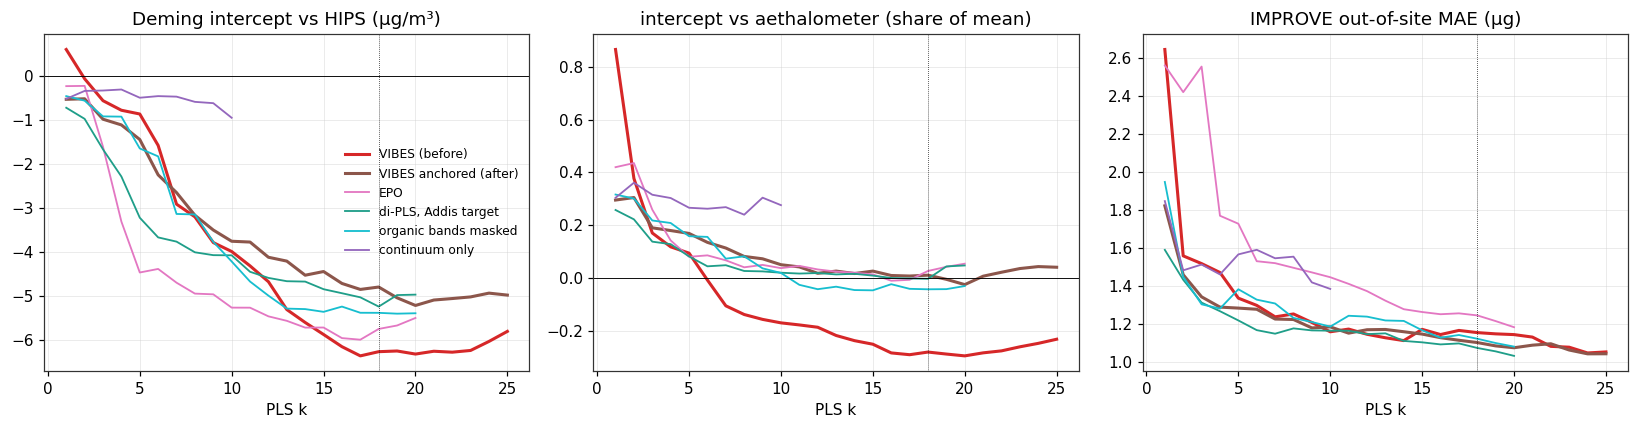

In [11]:
MS = {'vibes': ('#d62728', 'VIBES (before)'), 'vibes_anchorhp_full': ('#8c564b', 'VIBES anchored (after)'), 'epo': ('#e377c2', 'EPO'),
      'dipls_g10': ('#1f9e89', 'di-PLS, Addis target'), 'mask_org': ('#17becf', 'organic bands masked'), 'cont_only': ('#9467bd', 'continuum only')}
fig, axs = plt.subplots(1, 3, figsize=(15, 4))
for m, (c, lab) in MS.items():
    d = sw[sw.model == m]
    for ax, col in zip(axs, ['intercept_hips_bc', 'intercept_aeth_rel', 'improve_mae']):
        ax.plot(d.k, d[col], color=c, label=lab, lw=2 if m in ('vibes', 'vibes_anchorhp_full') else 1.2)
for ax, t in zip(axs, ['Deming intercept vs HIPS (µg/m³)', 'intercept vs aethalometer (share of mean)', 'IMPROVE out-of-site MAE (µg)']):
    ax.set(xlabel='PLS k', title=t); ax.axvline(18, color='k', lw=.5, ls=':')
axs[0].axhline(0, color='k', lw=.6); axs[1].axhline(0, color='k', lw=.6); axs[0].legend(frameon=False, fontsize=8)
fig.tight_layout(); fig.savefig(FIG / 'fig8_intercept_fixes.png', dpi=200)

,code,n,hips_ug,y,intercept,intercept_rel,loglog,r2,rho_ratio_vs_aeth
0,CHTS,61,8.744,HIPS BC (MAC 10),0.250,0.172,0.756,0.775,-0.469
1,CHTS,61,8.744,SPARTAN published FTIR EC,-0.252,-0.157,0.804,0.598,-0.288
2,CHTS,61,8.744,VIBES k18 (before),-0.291,-0.194,0.875,0.627,-0.185
3,CHTS,61,8.744,VIBES anchored k18 (after),-0.211,-0.135,0.864,0.628,-0.188
4,CHTS,61,8.744,EPO k18,0.061,0.038,0.748,0.592,-0.395
5,ETAD,170,34.172,HIPS BC (MAC 10),2.797,0.575,0.441,0.794,-0.916
6,ETAD,170,34.172,SPARTAN published FTIR EC,0.033,0.006,1.006,0.896,0.014
7,ETAD,170,34.172,VIBES k18 (before),-1.010,-0.280,1.284,0.880,0.395
8,ETAD,170,34.172,VIBES anchored k18 (after),0.039,0.009,0.998,0.876,-0.004
9,ETAD,170,34.172,EPO k18,0.122,0.024,0.979,0.875,-0.045


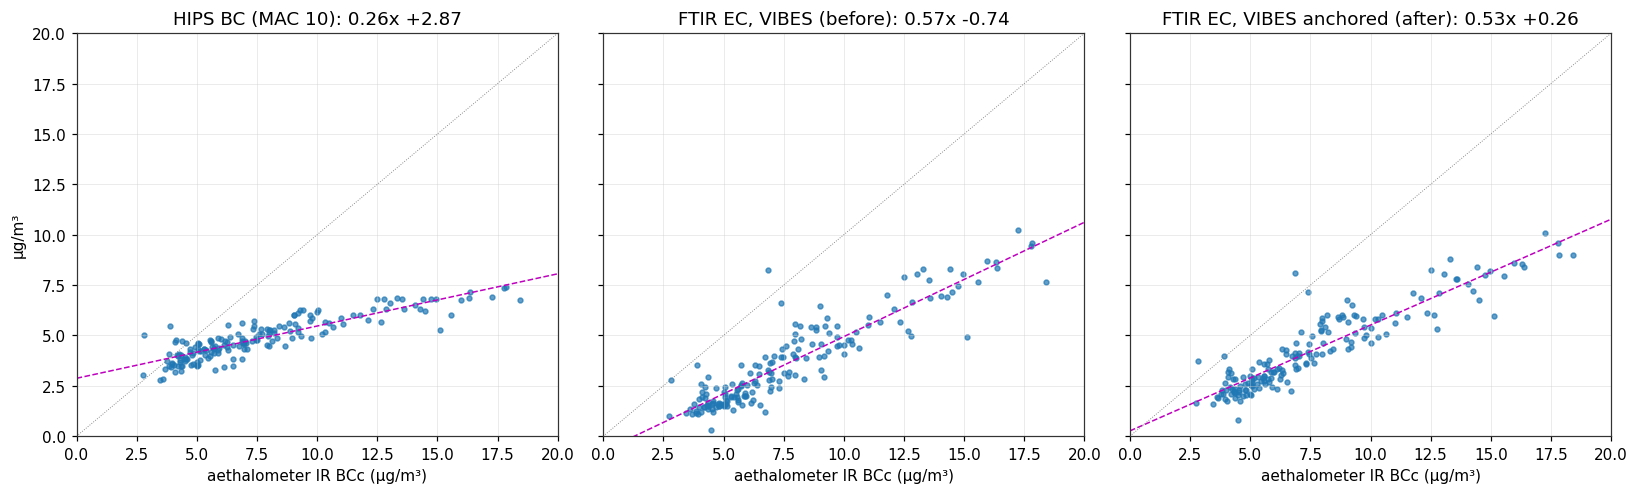

In [12]:
# aeth_ir: MA350 IR BCc per filter (gallery/data/export_aethalometer.py), joined by the workflow
a = pd.read_csv(I / 'addis_predictions.csv')   # µg/m³; 'base' = VIBES anchored on the channel-pair grid
a = a[~a.excluded & (a.aeth_ir > 0) & a.hips_bc.notna()]
fig, axs = plt.subplots(1, 3, figsize=(15, 4.6), sharex=True, sharey=True)
for ax, (col, lab) in zip(axs, [('hips_bc', 'HIPS BC (MAC 10)'), ('vibes k18', 'FTIR EC, VIBES (before)'), ('base k18', 'FTIR EC, VIBES anchored (after)')]):
    ax.scatter(a.aeth_ir, a[col], s=10, alpha=.7)
    s_, i_ = np.polyfit(a.aeth_ir, a[col], 1); xx = np.array([0, 20]); ax.plot(xx, s_ * xx + i_, 'm--', lw=1)
    ax.plot(xx, xx, color='grey', lw=.6, ls=':'); ax.set(title=f'{lab}: {s_:.2f}x {i_:+.2f}', xlabel='aethalometer IR BCc (µg/m³)', xlim=(0, 20), ylim=(0, 20))
axs[0].set_ylabel('µg/m³'); fig.tight_layout(); fig.savefig(FIG / 'fig9_aethalometer.png', dpi=200)
display(pd.read_csv(I / 'aeth_sites.csv')[['code', 'n', 'hips_ug', 'y', 'intercept', 'intercept_rel', 'loglog', 'r2', 'rho_ratio_vs_aeth']].round(3))

**What this says**

* **Gain, not offset.** Production VIBES takes most of its extra Addis gain from the PTFE bend and the edge of the C–F
  doublet (600–500 and 1300–1250 cm⁻¹). On the anchored background, neighbouring windows trade large shares (O–H/N–H,
  C–H and 1600–1500 against 4000–3700 and 3400–3100), because the continuum is read as differences between windows.
* **No label-free retraining flattens the HIPS slope.** Low k and continuum-only make the intercept smaller only by giving up
  level. Every candidate that gets the level right (EPO, di-PLS, importance weights) reads 1.9–2.2x HIPS with an intercept of
  −5 to −6 µg/m³. EPO moves the level most (Addis 1.05 of the TOR yardstick, IMPROVE heavy low-OC/EC 0.93) but costs IMPROVE
  accuracy (MAE 1.24 µg against 1.10). Importance weights overshoot on about 830 effective filters.
* **Against the aethalometer the anchored FTIR has no intercept.** It is proportional (Deming intercept +0.04 µg/m³, 1 % of
  the mean; log-log slope 1.00), the same as SPARTAN's published FTIR. Production VIBES is not (−1.0 µg/m³, −28 %, log-log
  1.28): that intercept was real and the anchored background removed it.
* **HIPS is the compressed one at Addis.** HIPS = 0.27 × aethalometer + 2.8 µg/m³ (log-log 0.44), and its ratio to the
  aethalometer falls with the aethalometer (ρ −0.92). FTIR's ratio doesn't (ρ 0.00). A noisy aethalometer would pull both
  ratios down together, so the compression is in HIPS. It is mild at Delhi, Beijing and Pasadena (0.73–0.77). Its cause
  is taken up in 8b and 8c.

**So:** the −5 µg/m³ against HIPS is mostly the reference, and it shouldn't be tuned away in the FTIR. Next steps:

* judge Addis on the aethalometer's intercept and linearity, and on the TOR yardstick's level;
* test HIPS linearity at heavy loading directly (IMPROVE TOR vs HIPS above 30 µg with OP > 0, or HIPS on dilution or
  half-loaded duplicates);
* then decide whether EPO's level gain is worth its IMPROVE cost.

Caveat: the aethalometer days are legacy daily aggregates matched by overlap (unverified 9 AM bins, checked against HIPS on
27 Oct), so they are noisier than the filters, but timing noise cannot make one instrument's ratio fall and not the other's.

### 8b. First test: is it filter loading? (stage `hips`)

Sampled volume is known exactly, so at a fixed BC concentration a filter that drew more air carries more BC. Regress
log(HIPS/FTIR) on log concentration and log volume, within sites. The volume coefficient is then a pure loading effect, free of
the errors-in-variables bias a concentration regressor carries. Sites are grouped by their median HIPS, never by the filter's
own HIPS. A saturation curve HIPS = true / (1 + true/Ls) is fitted where the volume effect vanishes, on heavy sites with
Ethiopia left out. Addis is then compared with HIPS linearised by it.

,group,reference,n,sites,median_hips_ug,sd_log_volume_within,coef,se
0,sites with median 0–8 µg,VIBES anchored k18,946,11,4.576,0.246,0.158,0.054
1,sites with median 0–8 µg,SPARTAN published,946,11,4.576,0.246,0.101,0.052
2,sites with median 8–14 µg,VIBES anchored k18,352,3,9.045,0.063,0.373,0.221
3,sites with median 8–14 µg,SPARTAN published,352,3,9.045,0.063,-0.007,0.249
4,sites with median 14–100 µg,VIBES anchored k18,1154,12,20.199,0.177,-0.255,0.042
5,sites with median 14–100 µg,SPARTAN published,1154,12,20.199,0.177,-0.246,0.035
6,ETAD only,VIBES anchored k18,231,1,33.735,0.016,-1.031,0.468
7,ETAD only,SPARTAN published,231,1,33.735,0.016,-1.257,0.472
8,INDH only,VIBES anchored k18,108,1,19.074,0.322,-0.253,0.085
9,INDH only,SPARTAN published,108,1,19.074,0.322,-0.359,0.070


,reference,Ls_ug,boot_p10,boot_p50,boot_p90,sites,n
0,VIBES anchored k18,62.4,47.5,63.1,143.7,"AEAZ, BDDU, BIBU, CLST, IDBD, INDH, INJA, MXMC...",902
1,SPARTAN published,66.2,51.0,68.1,123.9,"AEAZ, BDDU, BIBU, CLST, IDBD, INDH, INJA, MXMC...",902


                         model  slope  intercept  hips_c_loglog_aeth
20           SPARTAN published  0.333      0.920               1.053
21          VIBES k18 (before)  0.311     -0.260               1.053
22  VIBES anchored k18 (after)  0.286      0.673               1.053
23                     EPO k18  0.343      0.827               1.053


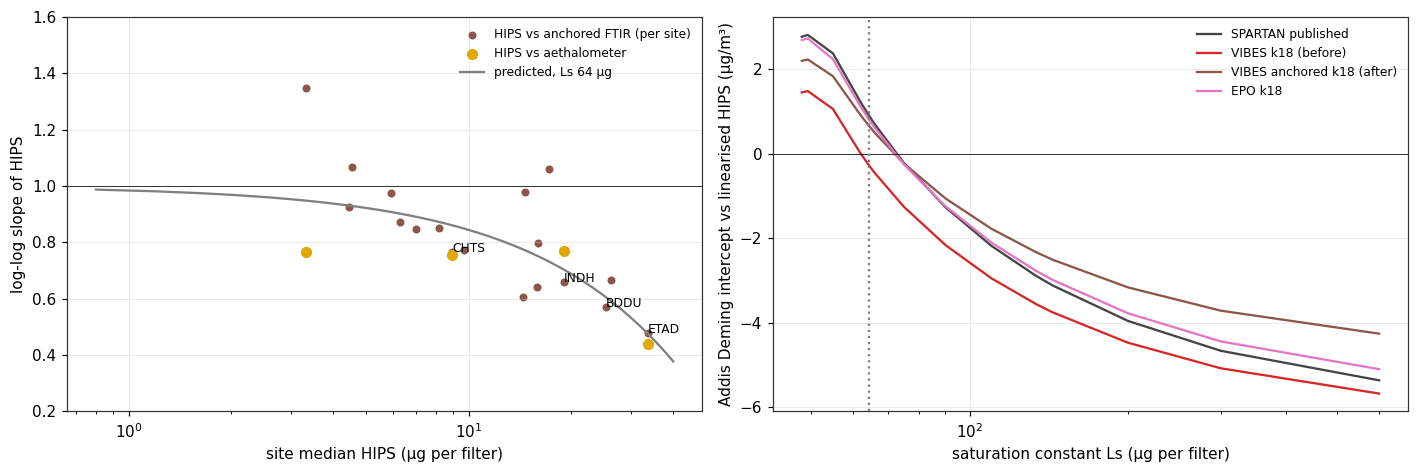

In [13]:
display(pd.read_csv(I / 'hips_volume_test.csv').round(3))
display(pd.read_csv(I / 'hips_saturation.csv').round(1))
hs = pd.read_csv(I / 'hips_sites_loglog.csv').sort_values('median_hips_ug')
hg = pd.read_csv(I / 'addis_vs_linearised_hips.csv'); hg = hg[np.isfinite(hg.Ls) & (hg.Ls >= 45)]
Ls = json.loads((I / 'hips_receipt.json').read_text())['Ls_used']
fig, axs = plt.subplots(1, 2, figsize=(13, 4.4))
ok = hs.r_ftir_ug >= .6
axs[0].scatter(hs.median_hips_ug[ok], hs.rma_vs_ftir_ug[ok], color='#8c564b', s=18, label='HIPS vs anchored FTIR (per site)')
axs[0].scatter(hs.median_hips_ug, hs.loglog_vs_aeth, color='#e0a800', s=40, label='HIPS vs aethalometer')
xx = np.linspace(.8, 40, 100); axs[0].plot(xx, 1 - xx / Ls, color='grey', label=f'predicted, Ls {Ls:.0f} µg')
for c in ('ETAD', 'INDH', 'BDDU', 'CHTS'):
    r = hs[hs.code == c].iloc[0]; axs[0].annotate(c, (r.median_hips_ug, r.rma_vs_ftir_ug), fontsize=8)
axs[0].set(xscale='log', xlabel='site median HIPS (µg per filter)', ylabel='log-log slope of HIPS', ylim=(.2, 1.6)); axs[0].axhline(1, color='k', lw=.5)
axs[0].legend(frameon=False, fontsize=8)
for m, c in [('SPARTAN published', '#444'), ('VIBES k18 (before)', '#d62728'), ('VIBES anchored k18 (after)', '#8c564b'), ('EPO k18', '#e377c2')]:
    d = hg[hg.model == m]; axs[1].plot(d.Ls, d.intercept, color=c, label=m)
axs[1].axhline(0, color='k', lw=.5); axs[1].axvline(Ls, color='grey', ls=':')
axs[1].set(xscale='log', xlabel='saturation constant Ls (µg per filter)', ylabel='Addis Deming intercept vs linearised HIPS (µg/m³)')
axs[1].legend(frameon=False, fontsize=8); fig.tight_layout(); fig.savefig(FIG / 'fig10_hips_saturation.png', dpi=200)
print(hg[hg.Ls.round(0) == round(Ls)][['model', 'slope', 'intercept', 'hips_c_loglog_aeth']].round(3))

**What this shows, and its limit.** At sites with a median of 14 µg per filter or more, more air at the same
concentration goes with a lower HIPS/FTIR (−0.25 ± 0.04), and a curve fitted without Ethiopia gives Ls ≈ 64 µg per filter
(80 %: about 49–134), which lands on Addis's compression. Section 8c shows that this overstates the case: most of the
volume signal comes from sites where volume isn't independent of concentration. Keep Ls as a what-if, not a measurement.

### 8c. Stress tests, and where we go from here (stage `stress`)

1. Is volume really independent of concentration? Not at Delhi or Bhaktapur. Split the heavy sites, and use PM2.5 as an
   independent concentration control, with site × quarter effects.
2. A better test: HIPS optical depth τ (before any MAC) against aethalometer BC per filter at the four sites with both, using
   raw HIPS from `Filter Data/unified_filter_dataset.pkl`. Fit on the other sites and predict Addis.
3. The Addis level, read from each anchor.
4. Does the season effect survive with the aethalometer taken out?

,code,n,median_hips_ug,sd_log_volume,r_volume_concentration,coef_ftir,se_ftir,coef_pub,se_pub
0,INDH,108,19.07,0.32,-0.73,-0.25,0.09,-0.36,0.07
1,BDDU,46,25.32,0.29,-0.80,-0.53,0.07,-0.46,0.08
2,AEAZ,63,18.28,0.27,-0.23,-0.24,0.12,-0.22,0.12
3,CLST,163,14.42,0.21,-0.13,-0.17,0.09,-0.08,0.06
4,ZAPR,190,14.61,0.15,-0.22,-0.41,0.14,-0.25,0.12
5,ZAJB,202,17.23,0.15,0.06,0.32,0.12,0.11,0.09
6,MXMC,30,15.96,0.11,-0.04,-0.12,0.21,-0.23,0.19
7,BIBU,34,26.17,0.04,-0.51,-0.55,0.55,0.18,0.46
8,ETAD,231,33.73,0.02,0.01,-1.03,0.47,-1.26,0.47
9,INJA,47,15.88,0.01,0.02,-1.06,2.90,0.60,2.56


,group,reference,control,coef,se,n
0,volume independent of concentration,VIBES anchored k18,own concentration,-0.164,0.064,648
1,volume independent of concentration,VIBES anchored k18,PM2.5 concentration,-0.110,0.080,648
2,volume independent of concentration,VIBES anchored k18,"PM2.5, site × quarter",-0.077,0.077,632
3,volume independent of concentration,SPARTAN published,own concentration,-0.117,0.051,648
4,volume independent of concentration,SPARTAN published,PM2.5 concentration,-0.063,0.063,648
5,volume independent of concentration,SPARTAN published,"PM2.5, site × quarter",-0.012,0.064,632
6,volume tied to concentration,VIBES anchored k18,own concentration,-0.343,0.062,154
7,volume tied to concentration,VIBES anchored k18,PM2.5 concentration,-0.365,0.090,154
8,volume tied to concentration,VIBES anchored k18,"PM2.5, site × quarter",-0.369,0.103,154
9,volume tied to concentration,SPARTAN published,own concentration,-0.347,0.061,154


,trained_on,n,model,p1,p2,addis_bias_log,addis_rmse_log,predicted_loglog,observed_loglog
0,Beijing + Pasadena + Delhi,155,proportional,0.027,NaN,0.325,0.415,1.000,0.441
1,Beijing + Pasadena + Delhi,155,saturating with loading,0.031,2.068,-0.116,0.165,0.553,0.441
2,Beijing + Pasadena + Delhi,155,saturating with concentration,10.389,20.174,0.106,0.192,0.723,0.441
3,Pasadena + Delhi,89,proportional,0.022,NaN,0.135,0.291,1.000,0.441
4,Pasadena + Delhi,89,saturating with loading,0.024,3.659,-0.092,0.187,0.734,0.441
5,Pasadena + Delhi,89,saturating with concentration,8.233,51.424,0.051,0.214,0.867,0.441
6,Beijing + Delhi,90,proportional,0.030,NaN,0.439,0.509,1.000,0.441
7,Beijing + Delhi,90,saturating with loading,0.046,1.116,-0.273,0.298,0.314,0.441
8,Beijing + Delhi,90,saturating with concentration,14.026,8.680,0.109,0.159,0.536,0.441


,code,n,hips_over_aeth,hips_over_aeth_lightest_third,ftir_over_aeth,published_over_aeth
0,CHTS,66,1.21,1.55,1.20,1.35
1,ETAD,171,0.69,0.86,0.54,0.65
2,INDH,24,0.71,0.79,0.68,0.78
3,USPA,65,0.80,0.85,0.76,0.75


,anchor,addis_true_over_hips
0,"curve, Beijing + Pasadena + Delhi",1.88
1,"curve, Pasadena + Delhi",1.36
2,"curve, Beijing + Delhi",7.63


,y,n,loglog,bega_vs_belg,bega_se,kiremt_vs_belg,kiremt_se
0,HIPS BC,170,0.452,-0.018,0.020,-0.027,0.022
1,VIBES k18 (before),170,1.143,-0.125,0.052,0.134,0.058
2,VIBES anchored k18 (after),170,0.879,-0.144,0.035,0.081,0.039
3,SPARTAN published,170,0.895,-0.143,0.035,0.072,0.039


{'clean_sites': ['AEAZ', 'CLST', 'ZAPR', 'ZAJB', 'MXMC'], 'confounded_sites': ['INDH', 'BDDU'], 'soil_median_ugm3': 4.1484566, 'soil_absorption_Mm1_at_0p05': 0.20742283000000003, 'hips_offset_Mm1': 28.0, 'tau_inf_boot': [1.7535401894825355, 2.0931534566648216, 2.4907701821422474], 'a_boot': [0.029308960278337286, 0.030727495950757897, 0.03213569068023927], 'curve': {'a': 0.030724902209393345, 'tau_inf': 2.068373913683672}, 'addis_tau_dAIC_quadratic_minus_linear': -10.68474899615012, 'raw_hips': 'research/ftir_hips_chem/Filter Data/unified_filter_dataset.pkl', 'created': '2026-11-04T00:35:16Z'}


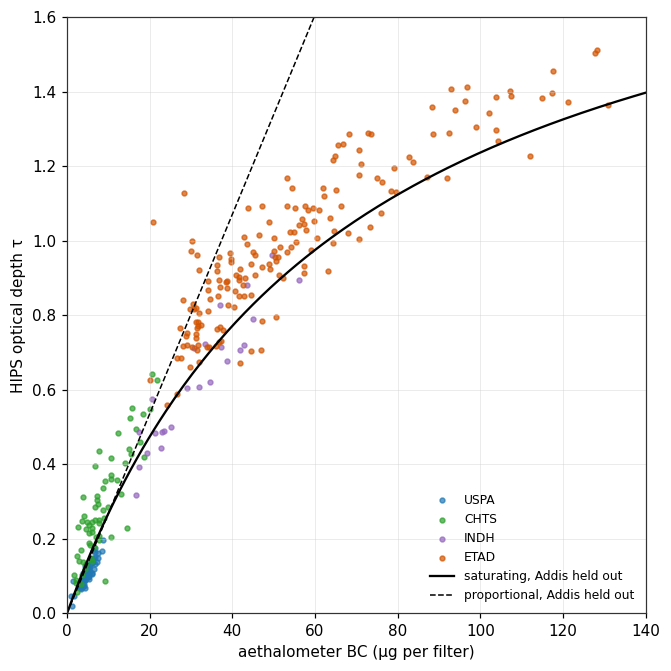

In [14]:
display(pd.read_csv(I / 'hips_volume_by_site.csv').round(2))
display(pd.read_csv(I / 'hips_volume_stress.csv').drop(columns='sites').round(3))
hold = pd.read_csv(I / 'hips_tau_holdout.csv'); display(hold.round(3))
tp = pd.read_csv(I / 'hips_tau_points.csv')
fig, ax = plt.subplots(figsize=(6.2, 6.2))
for c, col in {'USPA': '#1f77b4', 'CHTS': '#2ca02c', 'INDH': '#9467bd', 'ETAD': '#d35400'}.items():
    s_ = tp[tp.code == c]; ax.scatter(s_.aeth_ug, s_.tau, s=10, alpha=.7, color=col, label=c)
h3 = hold[hold.trained_on == hold.trained_on.iloc[0]].set_index('model')
xx = np.linspace(0, 140, 200); a_, ti = h3.loc['saturating with loading', ['p1', 'p2']]
ax.plot(xx, a_ * xx / (1 + a_ * xx / ti), 'k', label='saturating, Addis held out')
ax.plot(xx[xx < 62], h3.loc['proportional', 'p1'] * xx[xx < 62], 'k--', lw=1, label='proportional, Addis held out')
ax.set(xlabel='aethalometer BC (µg per filter)', ylabel='HIPS optical depth τ', xlim=(0, 140), ylim=(0, 1.6)); ax.legend(frameon=False, fontsize=8)
fig.tight_layout(); fig.savefig(FIG / 'fig11_hips_tau_curve.png', dpi=200)
display(pd.read_csv(I / 'aeth_bridge.csv').round(2)); display(pd.read_csv(I / 'addis_true_over_hips.csv').round(2))
display(pd.read_csv(I / 'addis_season_vs_aeth.csv').round(3))
print(json.loads((I / 'stress_receipt.json').read_text()))

**What this says**

* **The saturation reading doesn't hold as first stated.** Where volume is independent of concentration (Abu Dhabi, Santiago,
  Pretoria, Johannesburg, Mexico City), the strictest control gives −0.08 ± 0.08 against anchored FTIR and −0.01 ± 0.06
  against published, where Ls 64 predicts about −0.25. The strong signal comes from Delhi and Bhaktapur, where low-volume
  filters fall in different sampling periods. Johannesburg and Pretoria are heavy but show no compression at all.
* **HIPS is non-linear against an independent measure, and that does hold.** With the aethalometer on x, τ bends over across
  the four sites. A curve fitted without Addis predicts Addis to −11 %, against +38 % for a straight line, and the quadratic
  now beats the linear fit at Addis (ΔAIC −10.7). That updates `hips_offset_narrative.ipynb`, whose linear result used FTIR EC
  on x. The Addis "optical floor" could be the top of one shared curve.
* **Loading or concentration: unresolved.** Loading wins two training sets and concentration the third, and the fit is
  sensitive to the sites used (τ∞ 1.1–3.7). Delhi, the only site with a different volume, has 24 filters here.
* **Not dust.** Addis soil gives about 0.2 Mm⁻¹ at 633 nm, against the 28 Mm⁻¹ offset.
* **The season effect is in FTIR.** With the aethalometer taken out, anchored FTIR reads Bega −14 % and Kiremt +8 % against
  Belg (± 4 %), and HIPS −2 % and −3 %.
* **The level is not settled, and may be worse.** If HIPS is low at Addis (about ×1.4–1.9 on the two usable curves), FTIR's
  shortfall is larger than FTIR/HIPS suggests. FTIR/aethalometer is 0.54 at Addis, 0.76 Pasadena, 0.68 Delhi and 1.20 Beijing, so
  the aethalometer can't set a single level either.

**Where we go from here**

No new data needed:
1. Replace production VIBES with the anchored background at Addis (team decision).
2. Stop using slope and intercept against raw HIPS as the Addis failure metric; use the aethalometer's intercept and the
   TOR yardstick's level. Recheck the k-sweep and the poster's Addis fit.
3. Carry the season result onto the aethalometer.
4. Don't ship a retrained model; keep EPO as a level sensitivity bound.

Needs someone else:
5. Ask UC Davis for HIPS's τ limit and flagging policy (43 % of Addis filters exceed τ 1).
6. Paired Addis filters at half and full volume on the same days would separate loading from concentration.
7. The Addis city TOR filters are the only direct test of the level. Settle the pass rule before reading them (proposal in
   the gallery at `#xc-proposal` and in `docs/open-items.md`).

### 8d. Flow, the whole-network HIPS curve and the TOR test (`workflows/run_hips_response_20261103.py`)

**Flow.** The MA350 target is Flow2:Flow1 = 1:3 (75:25). Beijing (65:35) and Pasadena (71:29) were moved towards it from about 55:45,
Delhi climbs through its record with no step, and Addis MA350-0238 stayed at 55:45 throughout. BCc, the dual-spot compensated record,
is what carries the data across this. It holds up. Inside Addis, adjusted for loading, it about halves the flow effect seen on the
uncompensated spots (published FTIR −10 % on BC1, −3 % on BCc; anchored −15 %, −9 %; HIPS −11 %, −8 %), and BCc/BC1 itself moves −7 %
(−10 to −5) with no filter involved. Across the fixes HIPS/BCc doesn't move: Pasadena +1 % (−12 to +17), Delhi 0 % (−12 to +14),
Beijing −1 % (−18 to +19). An earlier version of this note gave about ±7 % inside Addis and 15 % at Pasadena. The first was computed
on BC1, not BCc, and the second was a raw median with no loading adjustment. HIPS stays compressed on BCc, BC1 and BC2. The absolute
level stays open for a calibration reason, not a flow one: the MA350 cross-section isn't a filter MAC, and the scale differs by site.

**HIPS across both networks.** Within sites, on filters binned on the geometric mean of the two optical depths, HIPS is flat to
τ ≈ 0.3 and then falls behind TOR and FTIR, in IMPROVE and SPARTAN alike. Fitted to IMPROVE TOR alone: τ0 = 0.27 (80 % 0.25–0.29).

**TOR.** No Addis city filters have arrived. The five Adama pairs fail both gates of the proposed rule, so it returns "not eligible".

,code,n,flow_ratio,p10,p90,bcc_over_bc1,f1_share,flow_status
0,CHTS,68,1.85,1.74,2.06,1.30,64.88,"fixed, below 1:3"
1,ETAD,171,1.19,1.10,1.30,1.60,54.43,unfixed
2,INDH,25,2.53,2.17,3.17,1.53,71.69,"rising, fix unconfirmed"
3,USPA,67,2.38,1.31,2.59,1.18,70.44,"fixed, below 1:3"


,months,era,n,flow_ratio,hips_over_bcc,hips_over_bc1,published_over_bcc,published_over_bc1,bcc_over_bc1
0,all months,after fix,53,2.42,0.82,0.95,0.75,0.89,1.18
1,all months,before fix,14,1.31,0.70,0.86,0.75,0.89,1.20
2,June to September only,after fix,38,2.39,0.81,0.96,0.75,0.94,1.16
3,June to September only,before fix,14,1.31,0.70,0.86,0.75,0.89,1.20


y,hips,pub,anch,hips,pub,anch,hips,pub,anch
x,BCc,BCc,BCc,BC1,BC1,BC1,BC2,BC2,BC2
code,,,,,,,,,
CHTS,-1.0,-23.6,2.2,-5.8,-28.7,-3.1,-3.7,-26.7,-1.2
ETAD,-8.3,-3.4,-8.8,-11.3,-10.0,-15.5,-13.4,-14.2,-19.6
INDH,-0.2,-35.4,-43.0,1.4,-33.7,-43.0,-4.2,-39.4,-47.1
USPA,1.5,-15.6,22.7,-2.9,-17.5,18.2,-5.2,-18.2,16.9


{'bcc_over_bc1': [1.4523655003176252, 1.6008185916093363, 1.7648904773874776], 'rho_compensation_vs_bc1': -0.2025437381954623, 'flow_ratio_p05_p95': [1.0772388350745343, 1.3187417014941496], 'compensation_vs_flow': {'CHTS': [-5.254879651383049, -10.589929030940759, 0.3985091677235708], 'ETAD': [-7.3114474258551, -9.679540312534396, -4.881266016383224], 'INDH': [1.4883214738746764, -3.344805337421042, 6.563122981037606], 'USPA': [-7.42532739934666, -13.663709706743077, -0.7361796759120298]}}


,fit,n,sites,tau0,tau0_lo,tau0_hi,c,c_lo,c_hi
0,all filters,11311,152,0.269,0.248,0.292,1.378,1.201,1.586
1,OC/EC < 2.5,794,121,0.393,0.343,0.482,2.321,1.800,3.133


,fit,correction_median,correction_p05,correction_p95,hips_loglog_aeth,raw_loglog_aeth,model,raw_slope,raw_intercept,slope,intercept,raw_ratio,ratio
0,all filters,1.713,1.391,2.314,0.773,0.441,VIBES k18 (before),2.059,-6.376,0.638,-2.079,0.616,0.363
1,all filters,1.713,1.391,2.314,0.773,0.441,VIBES anchored k18 (after),1.873,-4.867,0.582,-0.971,0.778,0.458
2,all filters,1.713,1.391,2.314,0.773,0.441,SPARTAN published,2.236,-5.882,0.692,-1.209,0.910,0.545
3,OC/EC < 2.5,1.301,1.147,1.569,0.645,0.441,VIBES k18 (before),2.059,-6.376,1.020,-3.097,0.616,0.472
4,OC/EC < 2.5,1.301,1.147,1.569,0.645,0.441,VIBES anchored k18 (after),1.873,-4.867,0.929,-1.892,0.778,0.601
5,OC/EC < 2.5,1.301,1.147,1.569,0.645,0.441,SPARTAN published,2.236,-5.882,1.107,-2.322,0.910,0.724


,code,n,tau_median,share_over_0p3,share_over_0p5,share_over_1,correction_median,raw_slope,raw_intercept_rel,slope,intercept_rel
0,ETAD,232,0.96,1.00,1.00,0.42,1.71,2.02,-1.34,0.53,-0.13
1,BDDU,46,0.72,1.00,0.98,0.04,1.43,0.88,-0.22,0.44,0.10
2,BIBU,53,0.67,0.96,0.85,0.17,1.37,1.15,-0.50,0.48,0.08
3,IDBD,47,0.59,0.98,0.74,0.00,1.29,1.83,-0.59,0.97,-0.11
4,INJA,71,0.57,0.89,0.58,0.15,1.27,1.94,-1.22,0.52,0.12
5,ETBI,26,0.55,1.00,0.54,0.00,1.25,0.72,-0.48,0.35,0.07
6,AEAZ,70,0.52,0.84,0.57,0.00,1.22,1.25,-0.98,0.62,-0.21
7,INDH,151,0.49,0.78,0.46,0.03,1.19,1.63,-0.34,1.06,-0.16
8,ZAJB,204,0.49,0.87,0.48,0.00,1.19,0.78,-0.07,0.38,0.34
9,MXMC,50,0.43,0.94,0.32,0.00,1.14,0.88,-0.06,0.49,0.30


,model,improve_error,improve_heavy_ratio,improve_light_ratio,n_heavy,n_light
0,raw,1.16,0.75,0.94,163,2065
1,spline,1.09,0.73,0.98,163,2065
2,vibes,1.15,0.73,0.97,163,2065
3,vibes_deflate,1.34,0.65,0.94,163,2065
4,vibes_anchorhp,1.10,0.77,0.96,163,2065
5,epo,1.24,0.91,0.92,163,2065


,date,ptfe_id,quartz_id,volume_m3,volume_ratio,flag,ec_tr_ugm3,ec_tt_ugm3,airspec_frozen_ugm3,vibes_frozen_ugm3,oc_tr_ugm3,quartz_volume_m3,deposit_area_cm2,tau,Fabs,Uncertainty,analysis,unflagged,tor_ug,VIBES k18 (before),VIBES anchored k18 (after),raw k18,EPO k18,ocec,fabs_over_tor,hips_bc
0,2024-07-09,J1269,J1693,2.88,1.10,start-offset,3.38,2.74,5.59,4.32,20.78,2.62,3.53,0.44,53.58,3.64,4746,False,9.73,3.96,4.82,6.44,4.27,6.15,15.86,5.36
1,2024-07-20,J1266,J1701,2.88,1.11,NaN,2.40,1.95,1.78,1.19,14.21,2.61,3.53,0.29,36.01,2.76,4745,True,6.91,2.07,2.84,5.13,1.84,5.93,15.02,3.60
2,2024-07-23,J1285,J1675,2.88,1.11,NaN,2.45,1.94,2.00,1.37,14.89,2.59,3.53,0.33,40.51,2.97,4748,True,7.06,2.34,3.21,5.47,2.50,6.08,16.54,4.05
3,2024-07-26,J1233,J1703,2.88,1.12,NaN,1.86,1.50,1.61,1.20,13.46,2.58,3.53,0.25,31.23,2.54,4744,True,5.36,1.86,2.68,4.87,1.98,7.23,16.77,3.12
4,2024-07-30,J1270,J1679,1.16,0.46,volume-mismatch,3.04,2.57,2.89,2.59,14.08,2.55,3.53,0.15,45.06,5.04,4747,False,3.53,3.89,5.60,9.17,4.01,4.63,14.82,4.51


,model,median_all,median_unflagged,mapped_lo,mapped_hi,mean_diff_ug_unflagged
0,VIBES k18 (before),1.00,0.96,0.76,1.26,-0.43
1,VIBES anchored k18 (after),1.43,1.31,1.09,1.72,1.93
2,raw k18,2.23,2.23,1.99,2.69,8.41
3,EPO k18,1.06,1.02,0.75,1.34,-0.37


,model,n_filters,true_level,eligible,observed_median,pass,fail,inconclusive
0,VIBES k18 (before),5,1.3,163,0.73,0.02,0.12,0.86
1,VIBES k18 (before),5,1.0,163,0.73,0.28,0.00,0.72
2,VIBES k18 (before),5,0.8,163,0.73,0.08,0.06,0.87
3,VIBES k18 (before),5,0.6,163,0.73,0.00,0.84,0.16
4,VIBES k18 (before),10,1.3,163,0.73,0.02,0.14,0.84
5,VIBES k18 (before),10,1.0,163,0.73,0.75,0.00,0.25
6,VIBES k18 (before),10,0.8,163,0.73,0.05,0.07,0.88
7,VIBES k18 (before),10,0.6,163,0.73,0.00,1.00,0.00
8,VIBES k18 (before),20,1.3,163,0.73,0.01,0.16,0.83
9,VIBES k18 (before),20,1.0,163,0.73,0.95,0.00,0.05


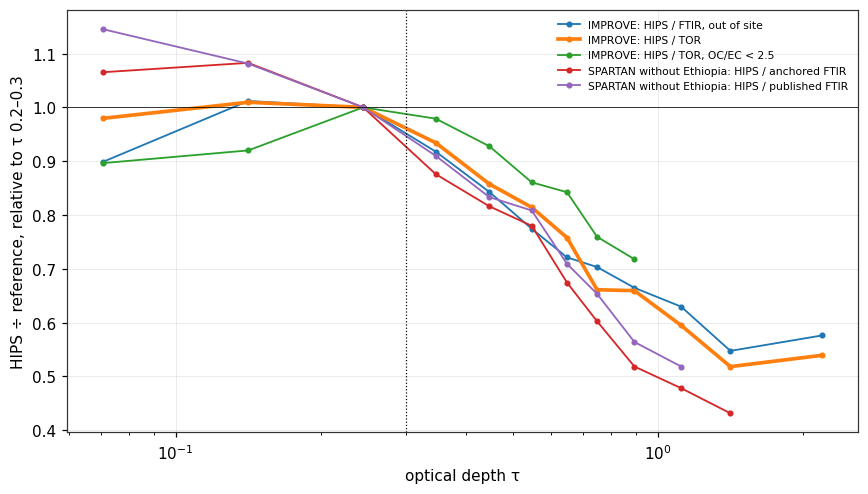

In [15]:
display(pd.read_csv(I / 'aeth_flow_by_site.csv').round(2)); display(pd.read_csv(I / 'aeth_fix_pasadena.csv').round(2))
fc = pd.read_csv(I / 'aeth_flow_coef.csv')
display(fc[fc.controls == 'loading'].pivot(index='code', columns=['y', 'x'], values='pct_over_range').round(1))
print(json.loads((I / 'aeth_flow_tests.json').read_text()))
cu = pd.read_csv(I / 'hips_tau_curves.csv')
fig, ax = plt.subplots(figsize=(8, 4.6))
for c, g in cu[cu.n >= 5].groupby('curve'):
    ax.plot(np.sqrt(g.lo.clip(lower=.05) * g.hi), g.ratio, marker='o', ms=3, label=c, lw=2.4 if c == 'IMPROVE: HIPS / TOR' else 1.2)
ax.set(xscale='log', xlabel='optical depth τ', ylabel='HIPS ÷ reference, relative to τ 0.2–0.3'); ax.axhline(1, color='k', lw=.5); ax.axvline(.3, color='k', ls=':', lw=.8)
ax.legend(frameon=False, fontsize=7); fig.tight_layout(); fig.savefig(FIG / 'fig12_hips_network_curve.png', dpi=200)
display(pd.read_csv(I / 'hips_response_fit.csv').round(3)); display(pd.read_csv(I / 'addis_vs_hips_response.csv').round(3)); display(pd.read_csv(I / 'hips_site_response.csv').head(12).round(2))
display(pd.read_csv(I / 'baseline_scoreboard.csv').round(2)); display(pd.read_csv(I / 'adama_tor_test.csv').round(2)); display(pd.read_csv(I / 'adama_tor_summary.csv').round(2))
display(pd.read_csv(I / 'pass_rule_simulation.csv').round(2))

**What this adds**

* **Working assumption for HIPS:** proportional below τ 0.3; use the IMPROVE TOR response or flag it above that; treat it as a lower
  bound above τ 1. Every Addis filter is above 0.3 and 42 % are above 1.
* **The correction helps without seeing Addis.** The anchored intercept goes from −4.87 to −0.97 µg/m³ (−1.89 on the low-OC/EC fit),
  and HIPS against the aethalometer from log-log 0.44 to 0.65–0.77. It overshoots at Johannesburg, Pretoria and Mexico City.
* **Anchored is not a clean win.** It removes a real intercept, but on Adama (lot 245) it reads 1.31 of TOR against 0.96 for
  production VIBES, and it's little better on IMPROVE's heavy Addis-like filters (0.77 against 0.73). The Adama excess looks like a lot
  offset: raw reads 2.23 there, and on IMPROVE's matching filters all baselines agree.
* **EPO is better than I first said.** It's closest to TOR on both direct checks (0.91 and 1.02), at an overall error of 1.24 µg
  against 1.10. Both are options in the gallery's FTIR baseline switch.
* **The Addis level is open.** HIPS looks ×1.3–1.7 low, but Adama's Fabs/TOR is about 16 m²/g rather than 10, on five filters from
  another site. Those pull in opposite directions.
* **The pass rule, simulated with 10 filters:** a true level of 1.0 passes 93 %, 0.6 fails 100 %, and 0.8 is inconclusive 89 %. Twenty
  filters take the 1.0 pass rate to 100 % but leave 0.8 inconclusive (92 %), because a level on a band edge stays unresolved by design.
  The rule now fails high as well as low, since anchored read 1.31 on Adama. It's a proposal for the team, not an agreed rule.